<a href="https://colab.research.google.com/github/ndnminh69/Spotify-Song-Pred/blob/main/V%C5%A9_H%E1%BB%93ng_Nhung.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Titanic.

## Giai đoạn 1 — Thu thập và đánh giá dữ liệu

In [ ]:
# Thư viện và
%pip -q install kagglehub
import kagglehub
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


du_lieu_goc = pd.read_csv("/content/train.csv")
print("Kích thước dữ liệu:", du_lieu_goc.shape)
display(du_lieu_goc.head())

Kích thước dữ liệu: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### 2. Kiểm tra cấu trúc, giá trị thiếu và dữ liệu trùng

In [ ]:
# Xem số dòng, cột và kiểu dữ liệu
print("Số dòng và cột:", du_lieu_goc.shape)
du_lieu_goc.info()
display(du_lieu_goc.describe(include="all").T)

Số dòng và cột: (891, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Dooley, Mr. Patrick",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292


In [ ]:
# Tính số lượng và tỷ lệ dữ liệu thiếu
bang_thieu = pd.DataFrame({
    "Số giá trị thiếu": du_lieu_goc.isna().sum(),
    "Tỷ lệ thiếu (%)": (du_lieu_goc.isna().mean() * 100).round(2)
})
print("Số dòng trùng hoàn toàn:", du_lieu_goc.duplicated().sum())
print("Số mã hành khách trùng:", du_lieu_goc["PassengerId"].duplicated().sum())
display(bang_thieu.sort_values("Tỷ lệ thiếu (%)", ascending=False))

Số dòng trùng hoàn toàn: 0
Số mã hành khách trùng: 0


,Số giá trị thiếu,Tỷ lệ thiếu (%)
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22
PassengerId,0,0.00
Name,0,0.00
Pclass,0,0.00
Survived,0,0.00
Sex,0,0.00
Parch,0,0.00
SibSp,0,0.00


## Giai đoạn 2 — Làm sạch và chuẩn bị dữ liệu

In [ ]:
# Tạo bản sao và làm sạch các trường cần phân tích
du_lieu = du_lieu_goc.copy()
du_lieu = du_lieu.drop_duplicates(subset="PassengerId")
du_lieu["Embarked"] = du_lieu["Embarked"].fillna(du_lieu["Embarked"].mode()[0])

# Tạo nhóm tuổi và số người thân đi cùng
du_lieu["Nhom_tuoi"] = pd.cut(
    du_lieu["Age"], bins=[0, 12, 18, 35, 60, 100],
    labels=["Trẻ em", "13–18", "19–35", "36–60", "Trên 60"],
    include_lowest=True
)
du_lieu["So_nguoi_than"] = du_lieu["SibSp"] + du_lieu["Parch"]
du_lieu["Di_mot_minh"] = du_lieu["So_nguoi_than"].eq(0).map({True:"Một mình",False:"Có người thân"})
du_lieu["Trang_thai"] = du_lieu["Survived"].map({0:"Không sống sót",1:"Sống sót"})
print("Số hành khách sau làm sạch:",len(du_lieu))
display(du_lieu[["Survived","Sex","Pclass","Age","Nhom_tuoi","So_nguoi_than","Embarked"]].head())

Số hành khách sau làm sạch: 891


,Survived,Sex,Pclass,Age,Nhom_tuoi,So_nguoi_than,Embarked
0,0,male,3,22.0,19–35,1,S
1,1,female,1,38.0,36–60,1,C
2,1,female,3,26.0,19–35,0,S
3,1,female,1,35.0,19–35,1,S
4,0,male,3,35.0,19–35,0,S


In [ ]:
# Kiểm tra giá vé bằng tứ phân vị IQR (chỉ nhận diện, không xóa)
q1 = du_lieu["Fare"].quantile(0.25)
q3 = du_lieu["Fare"].quantile(0.75)
iqr = q3 - q1
gioi_han_tren = q3 + 1.5 * iqr
so_ve_cao = (du_lieu["Fare"] > gioi_han_tren).sum()
print("Ngưỡng vé cao theo IQR:",round(gioi_han_tren,2))
print("Số vé vượt ngưỡng:",so_ve_cao)

Ngưỡng vé cao theo IQR: 65.63
Số vé vượt ngưỡng: 116
Không xóa vì vé hạng cao có thể thực sự đắt.


**Giải Trình:**

1.   Age: Giữ giá trị thiếu để tránh làm sai lệch phân bố tuổi.

2.  Embarked: Điền Mode vì là biến phân loại.

3.  Cabin: Không phân tích vì thiếu khoảng 77% dữ liệu.

4.  Trùng lặp: Kiểm tra và loại bỏ để tránh sai lệch kết quả.

5.  Outliers: Dùng IQR để phát hiện, không xóa vì giá vé cao có thể hợp lệ.
   



## Giai đoạn 3 — Thống kê, trực quan hóa và kiểm định


### 1. Tỉ lệ sống sót

Tỷ lệ sống sót : 38.4 %


,Số hành khách
Trang_thai,
Không sống sót,549
Sống sót,342


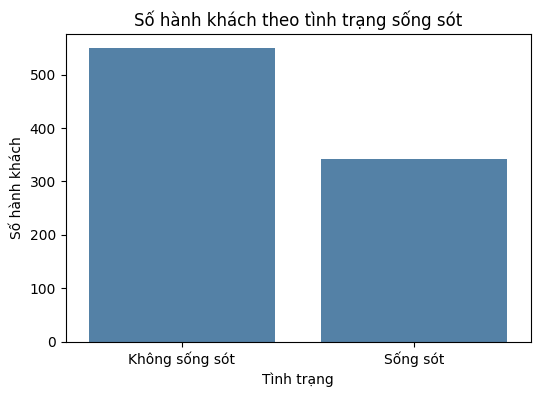

In [ ]:
# Đếm người sống sót và tính tỷ lệ chung
bang_song_sot = du_lieu["Trang_thai"].value_counts()
ty_le_chung = du_lieu["Survived"].mean() * 100
print("Tỷ lệ sống sót :",round(ty_le_chung,1),"%")
display(bang_song_sot.to_frame("Số hành khách"))
plt.figure(figsize=(6,4))
sns.countplot(data=du_lieu, color="steelblue", x="Trang_thai", order=["Không sống sót","Sống sót"])
plt.title("Số hành khách theo tình trạng sống sót")
plt.xlabel("Tình trạng")
plt.ylabel("Số hành khách")
plt.show()

### 2. Sự liên hệ giữa giới tính và tỉ lệ sống sót

,count,Tỷ lệ sống (%)
Sex,,
female,314,74.2
male,577,18.9


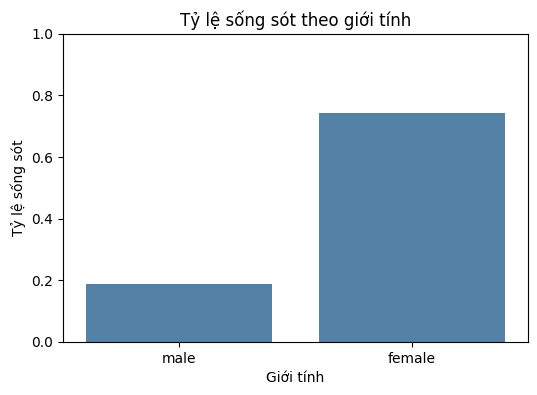

In [ ]:
# So sánh số lượng và tỷ lệ sống sót theo giới tính
bang_gioi_tinh = du_lieu.groupby("Sex")["Survived"].agg(["count","mean"])
bang_gioi_tinh["Tỷ lệ sống (%)"] = (bang_gioi_tinh["mean"]*100).round(1)
display(bang_gioi_tinh[["count","Tỷ lệ sống (%)"]])
plt.figure(figsize=(6,4))
sns.barplot(color="steelblue",data=du_lieu, x="Sex", y="Survived", errorbar=None)
plt.title("Tỷ lệ sống sót theo giới tính")
plt.xlabel("Giới tính")
plt.ylabel("Tỷ lệ sống sót")
plt.ylim(0,1)
plt.show()

**Nhận xét:** Nữ có tỉ lệ sống sót vượt trội so với Nam

### 3. Sự liên hệ giữa hạng vé và tỉ lệ sống sót

,count,Tỷ lệ sống (%)
Pclass,,
1,216,63.0
2,184,47.3
3,491,24.2


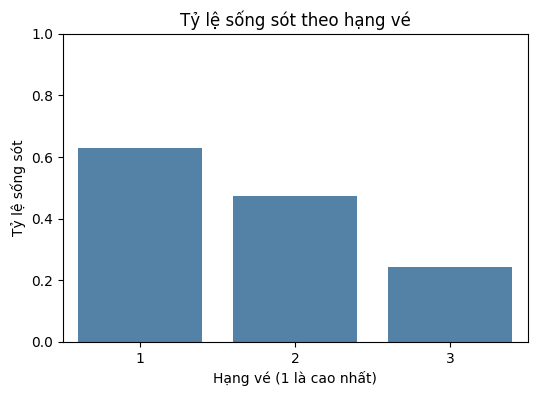

In [ ]:
# So sánh tỷ lệ sống sót theo hạng vé
bang_hang_ve = du_lieu.groupby("Pclass")["Survived"].agg(["count","mean"])
bang_hang_ve["Tỷ lệ sống (%)"] = (bang_hang_ve["mean"]*100).round(1)
display(bang_hang_ve[["count","Tỷ lệ sống (%)"]])
plt.figure(figsize=(6,4))
sns.barplot(color="steelblue",data=du_lieu, x="Pclass",y="Survived",errorbar=None)
plt.title("Tỷ lệ sống sót theo hạng vé")
plt.xlabel("Hạng vé (1 là cao nhất)")
plt.ylabel("Tỷ lệ sống sót")
plt.ylim(0,1)
plt.show()

**Nhận xét:** Hạng vé 1 có tỉ lệ sống sót cao hơn hạng vé 2, hạng vé 2 cũng có tỉ lệ sống sót cao hơn hạng vé 3.

### 4. Mối liên hệ giữa hạng vé và sống sót có khác nhau theo giới tính?

Pclass,1,2,3
Sex,,,
female,96.8,92.1,50.0
male,36.9,15.7,13.5


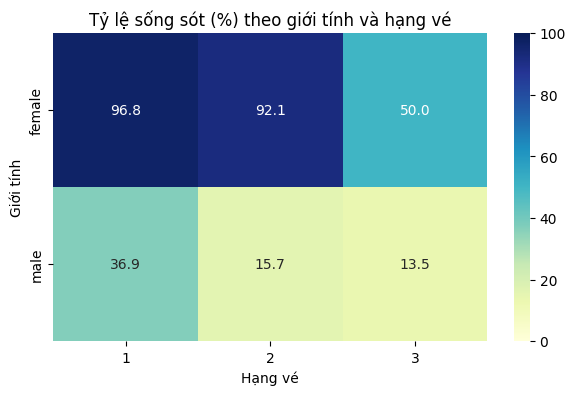

In [ ]:
# Tạo bảng tỷ lệ sống theo giới tính và hạng vé
bang_gioi_hang = du_lieu.pivot_table(values="Survived",index="Sex",columns="Pclass",aggfunc="mean")
display((bang_gioi_hang*100).round(1))
plt.figure(figsize=(7,4))
sns.heatmap(bang_gioi_hang*100,annot=True,fmt=".1f",cmap="YlGnBu",vmin=0,vmax=100)
plt.title("Tỷ lệ sống sót (%) theo giới tính và hạng vé")
plt.xlabel("Hạng vé")
plt.ylabel("Giới tính")
plt.show()

**Nhận xét:**

1.   Giới tính: Nữ có tỷ lệ sống sót cao hơn nam ở cả 3 hạng vé.

2.  Hạng vé: Hành khách hạng 1 có tỷ lệ sống sót cao hơn hạng 2 và hạng 3 ở cả hai giới.

3.  Nữ hạng 1 và 2: Có tỷ lệ sống sót rất cao, lần lượt là 96,8% và 92,1%.

4.  Nam hạng 3: Có tỷ lệ sống sót thấp nhất, chỉ 13,5%.




### 5. Sự liên hệ giữa tuổi và tỉ lệ sống sót

,count,Tỷ lệ sống (%)
Nhom_tuoi,,
Trẻ em,69,58.0
13–18,70,42.9
19–35,358,38.3
36–60,195,40.0
Trên 60,22,22.7


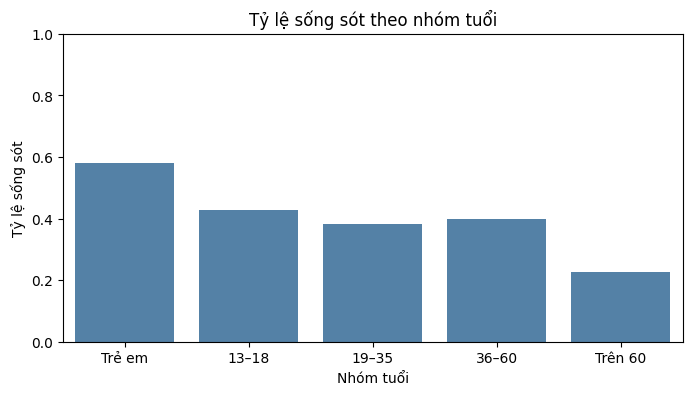

Số dòng thiếu tuổi không dùng trong câu này: 177


In [ ]:
# Bỏ các dòng thiếu tuổi trong riêng phần phân tích tuổi
du_lieu_co_tuoi = du_lieu.dropna(subset=["Age"]).copy()
bang_tuoi = du_lieu_co_tuoi.groupby("Nhom_tuoi",observed=True)["Survived"].agg(["count","mean"])
bang_tuoi["Tỷ lệ sống (%)"] = (bang_tuoi["mean"]*100).round(1)
display(bang_tuoi[["count","Tỷ lệ sống (%)"]])
plt.figure(figsize=(8,4))
sns.barplot(color="steelblue",data=du_lieu_co_tuoi,x="Nhom_tuoi",y="Survived",errorbar=None)
plt.title("Tỷ lệ sống sót theo nhóm tuổi")
plt.xlabel("Nhóm tuổi")
plt.ylabel("Tỷ lệ sống sót")
plt.ylim(0,1)
plt.show()
print("Số dòng thiếu tuổi không dùng trong câu này:",du_lieu["Age"].isna().sum())

**Nhận xét:** Tuổi càng trẻ thường có tỷ lệ sống sót cao hơn, đặc biệt là trẻ em. Tuy nhiên có 1 số dữ liệu thiếu tuổi nên tỷ lệ thực tế có thể khác.

### 6. So sánh tỷ lệ sống sót khi đi một mình và đi cùng người thân

,count,Tỷ lệ sống (%)
Di_mot_minh,,
Có người thân,354,50.6
Một mình,537,30.4


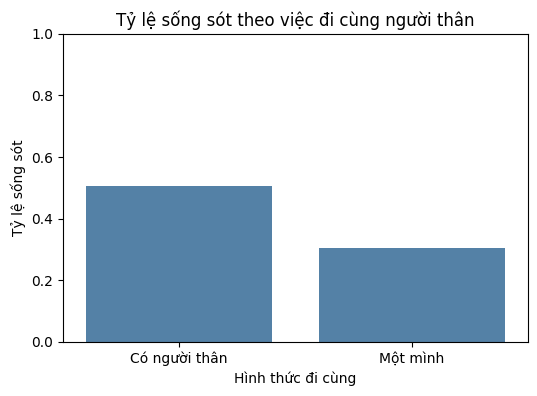

In [ ]:
# So sánh hành khách đi một mình với đi cùng người thân
bang_di_cung = du_lieu.groupby("Di_mot_minh")["Survived"].agg(["count","mean"])
bang_di_cung["Tỷ lệ sống (%)"] = (bang_di_cung["mean"]*100).round(1)
display(bang_di_cung[["count","Tỷ lệ sống (%)"]])
plt.figure(figsize=(6,4))
sns.barplot(color="steelblue",data=du_lieu,x="Di_mot_minh",y="Survived",errorbar=None)
plt.title("Tỷ lệ sống sót theo việc đi cùng người thân")
plt.xlabel("Hình thức đi cùng")
plt.ylabel("Tỷ lệ sống sót")
plt.ylim(0,1)
plt.show()

###  7. Kích thước nhóm và tỉ lệ sống sốt

,count,Tỷ lệ sống (%)
Nhom_gia_dinh,,
0 người,537,30.4
1–2 người,263,56.3
3–5 người,66,40.9
Trên 5 người,25,16.0


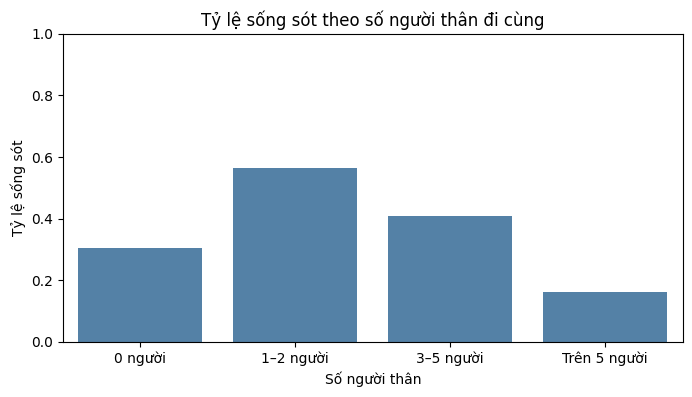

In [ ]:
# Nhóm số người thân để so sánh dễ hơn
du_lieu["Nhom_gia_dinh"] = pd.cut(
    du_lieu["So_nguoi_than"],bins=[-1,0,2,5,20],
    labels=["0 người", "1–2 người", "3–5 người", "Trên 5 người"]
)
bang_gia_dinh = du_lieu.groupby("Nhom_gia_dinh",observed=True)["Survived"].agg(["count","mean"])
bang_gia_dinh["Tỷ lệ sống (%)"] = (bang_gia_dinh["mean"]*100).round(1)
display(bang_gia_dinh[["count","Tỷ lệ sống (%)"]])
plt.figure(figsize=(8,4))
sns.barplot(color="steelblue",data=du_lieu,x="Nhom_gia_dinh",y="Survived",errorbar=None)
plt.title("Tỷ lệ sống sót theo số người thân đi cùng")
plt.xlabel("Số người thân")
plt.ylabel("Tỷ lệ sống sót")
plt.ylim(0,1)
plt.show()

**Nhận xét:** Tỷ lệ sống sót khi có 1-2 người thân đi cùng cao nhưng do số lượng cũng khá cao nên chưa thể đưa ra kết luận gì ở đây.

### Câu hỏi 9. Giới tính và tình trạng sống sót có liên quan không?
Sử dụng kiểm định Chi-square (5%).

In [ ]:
# Tạo bảng chéo và kiểm định Chi-square
from scipy.stats import chi2_contingency
bang_kiem_dinh = pd.crosstab(du_lieu["Sex"],du_lieu["Survived"])
chi_binh_phuong, gia_tri_p, bac_tu_do, bang_ky_vong = chi2_contingency(bang_kiem_dinh)
display(bang_kiem_dinh)
print("Giá trị p:",format(gia_tri_p,".6g"))
if gia_tri_p < 0.05:
    print("Có bằng chứng về mối liên hệ giữa giới tính và sống sót (p < 0,05).")
else:
    print("Chưa đủ bằng chứng về mối liên hệ (p >= 0,05).")

Survived,0,1
Sex,,
female,81,233
male,468,109


Giá trị p: 1.19736e-58
Có bằng chứng về mối liên hệ giữa giới tính và sống sót (p < 0,05).


**Nhận xét:** Có sự bằng chứng thống kê về sự liên quan giữa giới tính và tỉ lệ sống sót

## Giai đoạn 4 — Đánh giá tác động và khuyến nghị

**Nhận xét chung**
1. **Tỷ lệ chung:** 38.4% hành khách trong dữ liệu có kết quả sống sót.
2. **Giới tính:** Nhóm Nữ có tỷ lệ sống sót cao hơn nhóm Nam (74.2% so với 18.8%).
3. **Hạng vé:** Nhóm hạng 1 có tỷ lệ sống sót cao nhất với 63%

**Hạn chế dữ liệu:**
- `Age` và `Cabin` thiếu nhiều; một số phân nhóm có ít mẫu.
-  Không có data về các thông tin khác có thể ảnh hưởng đến khả năng sống sót như vị trị phòng, khả năng tiếp cần xuống cứu sinh.

**Hướng phát triển:** Bổ sung dữ liệu về thông tin về vị trí cabin, thời điểm sơ tán và khả năng tiếp cận xuồng cứu sinh để có thể phân tích tốt hơn tỉ lệ sống sót các nhóm.